In [1]:
import torch
import torchvision
from torchvision import models
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
import torch.nn as nn

from pathlib import Path
import matplotlib.pyplot as plt


from lightcurves import LC_DATA_PATH

In [2]:
MODEL_SAVE_PATH = Path('data/cnn/model_weights.pth')
SAMPLE_SIZE = 100

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.mps.is_available() else "cpu")
device

device(type='mps')

In [4]:
transform = transforms.Compose([
    transforms.Resize((224, 224)),  # Resizing the images to fit ResNet input
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])


In [5]:
dataset = torchvision.datasets.ImageFolder(root=LC_DATA_PATH, transform=transform)
sampler = torch.utils.data.RandomSampler(dataset, num_samples=100)
loader = DataLoader(dataset, batch_size=2, sampler=sampler)

In [6]:
model = models.resnet34(pretrained=True)
model.fc = nn.Linear(model.fc.in_features, 2)
model = torch.nn.DataParallel(model.to(device))
model.load_state_dict(torch.load(MODEL_SAVE_PATH))
model.eval()
# model.to(device)

/Users/adam/Code/lc-filter/.venv/lib/python3.13/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/Users/adam/Code/lc-filter/.venv/lib/python3.13/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet34_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet34_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


DataParallel(
  (module): ResNet(
    (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track

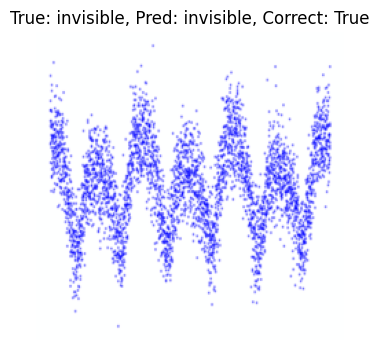

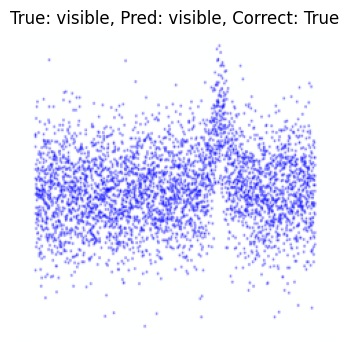

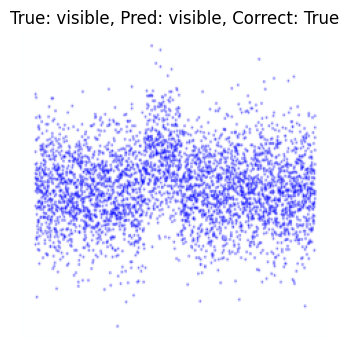

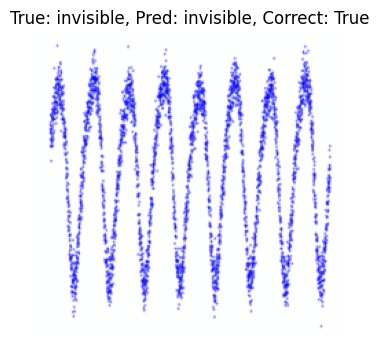

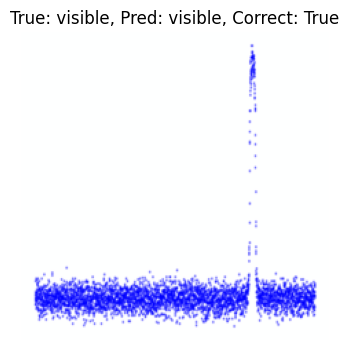

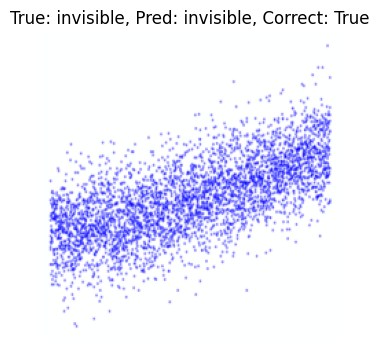

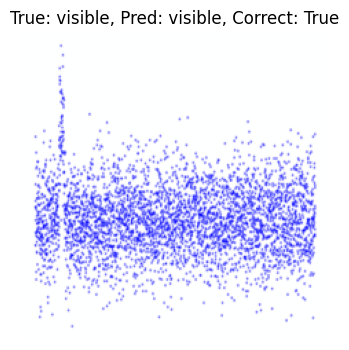

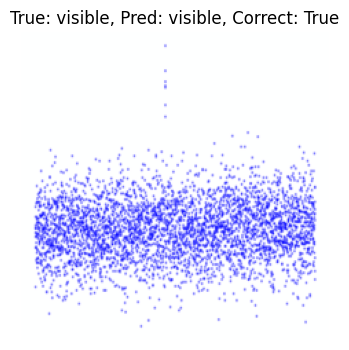

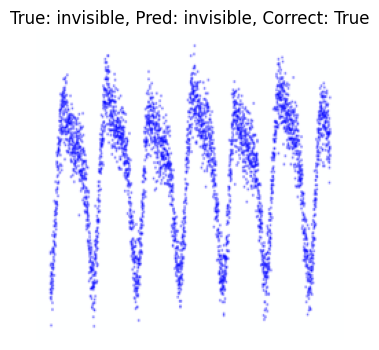

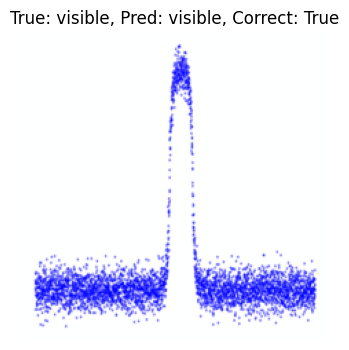

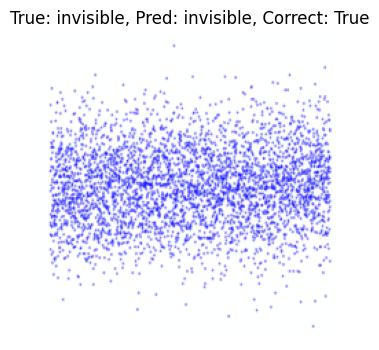

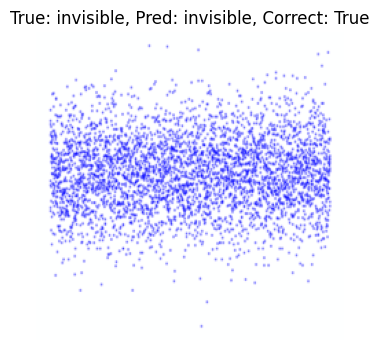

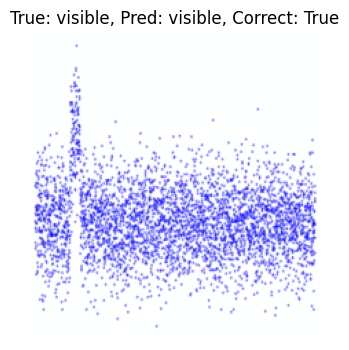

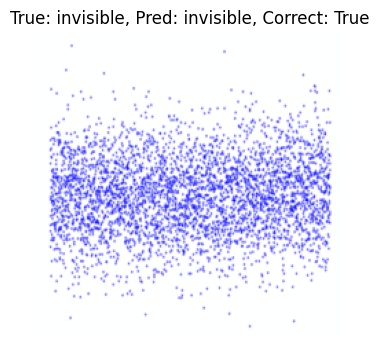

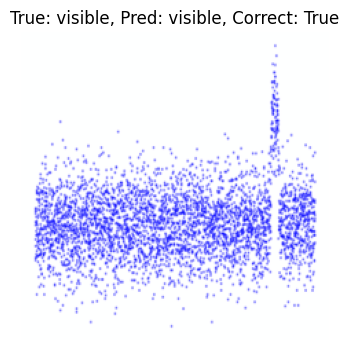

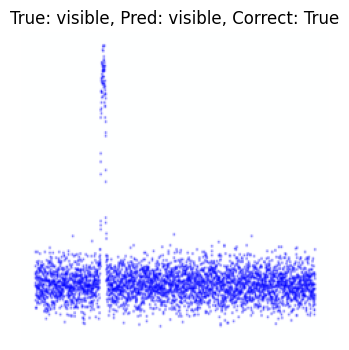

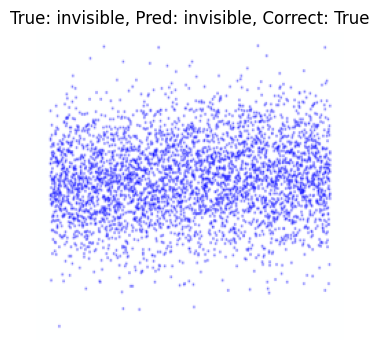

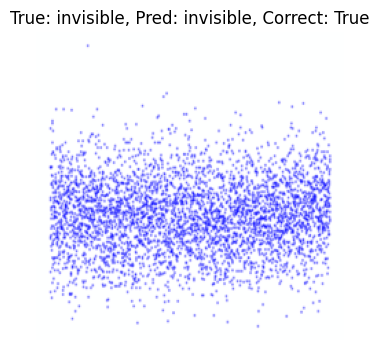

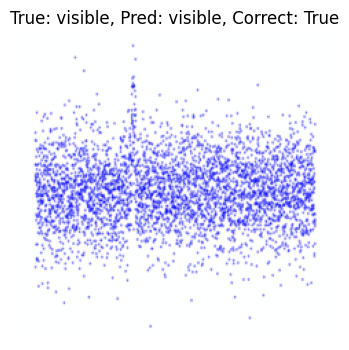

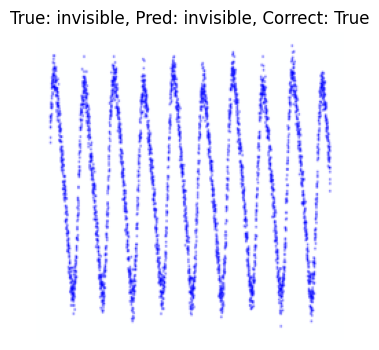

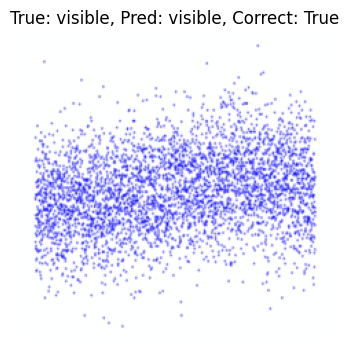

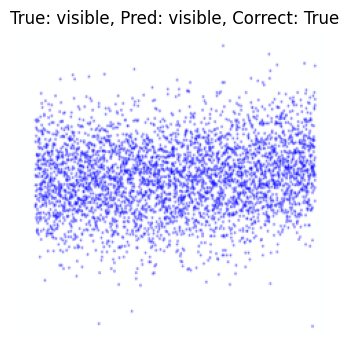

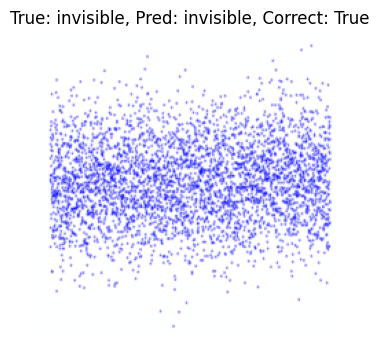

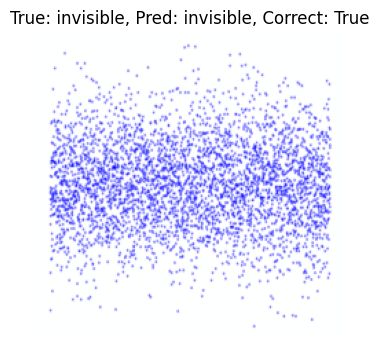

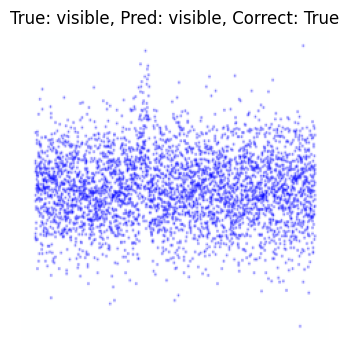

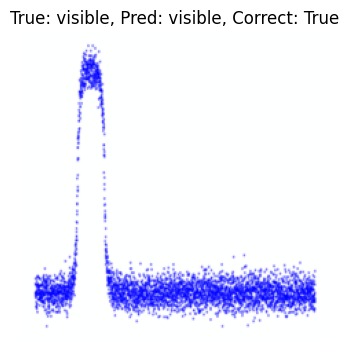

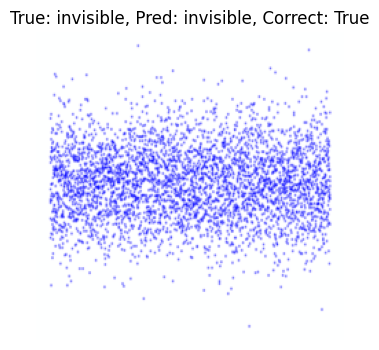

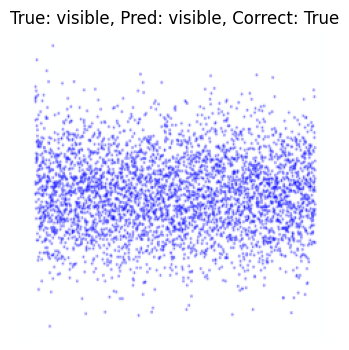

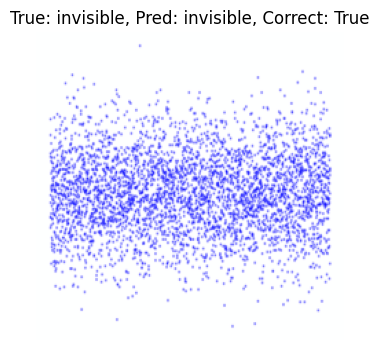

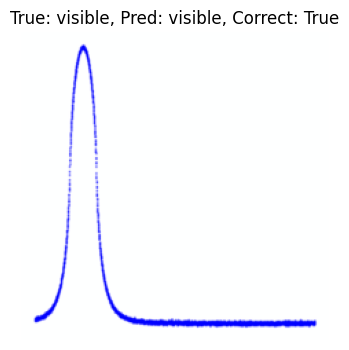

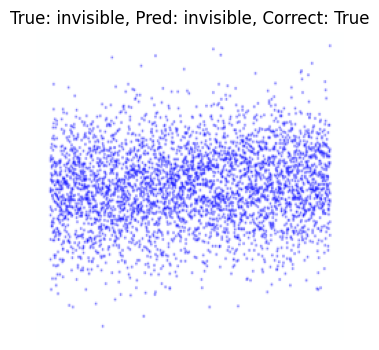

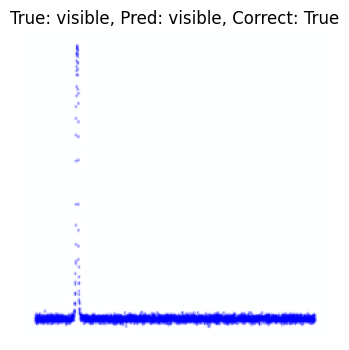

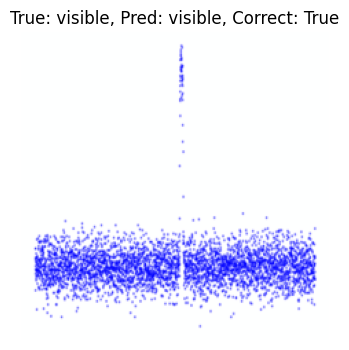

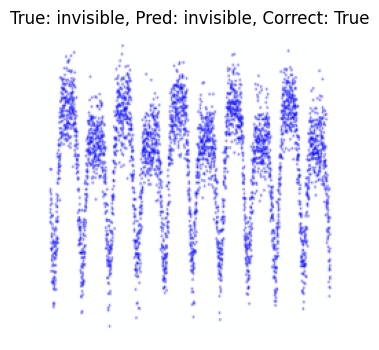

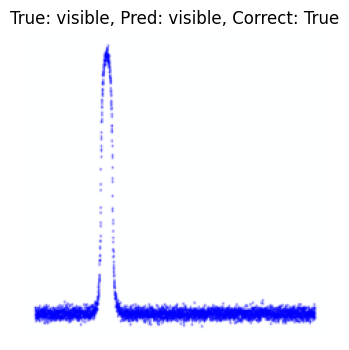

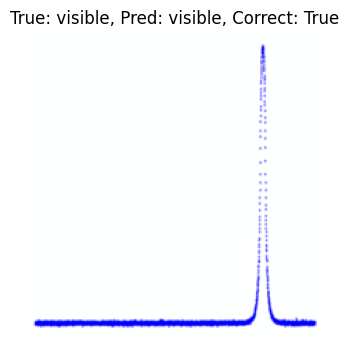

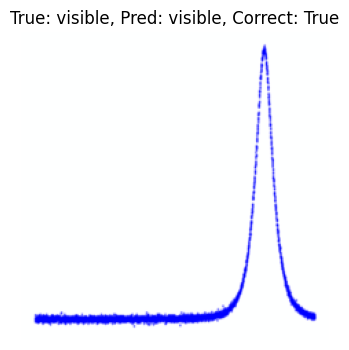

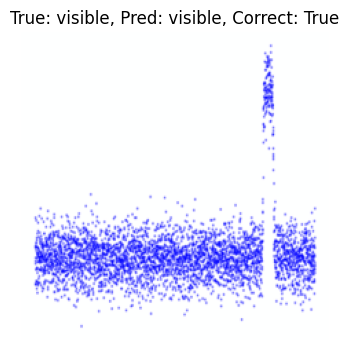

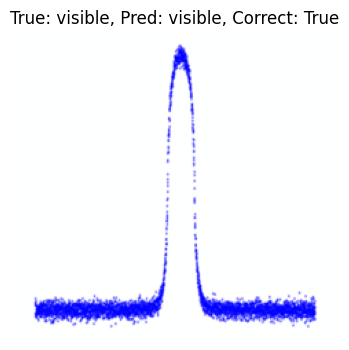

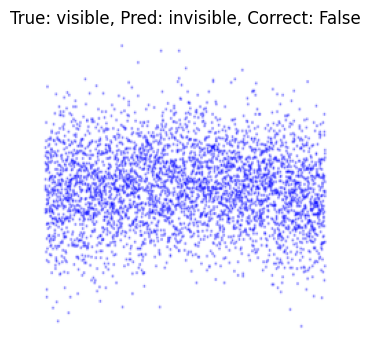

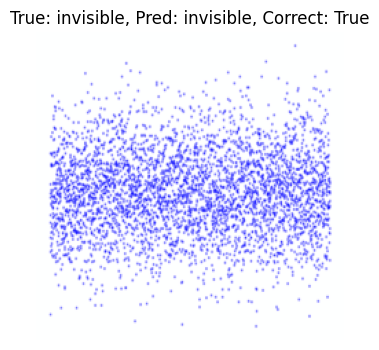

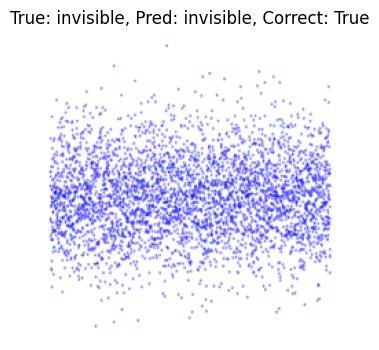

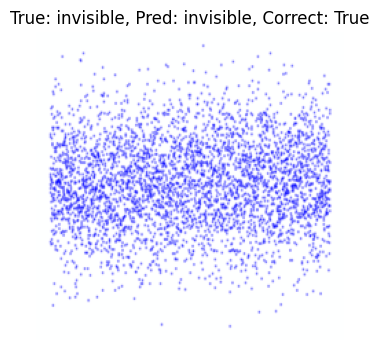

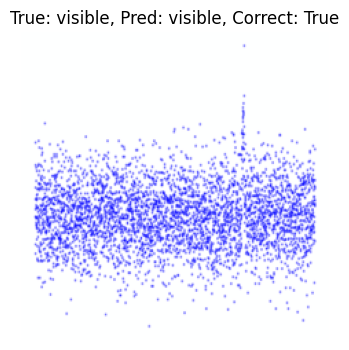

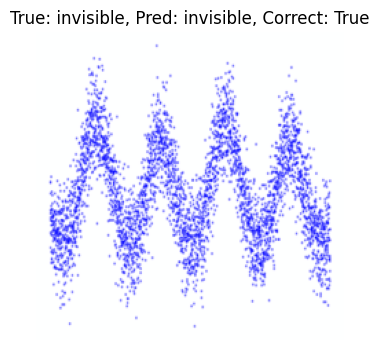

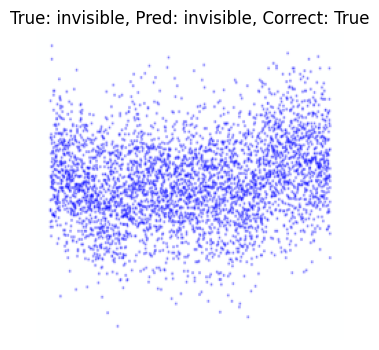

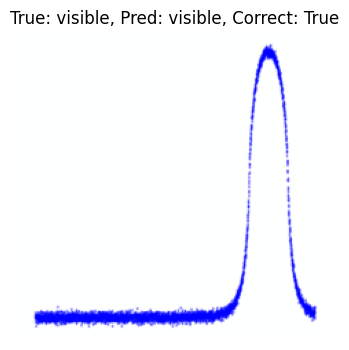

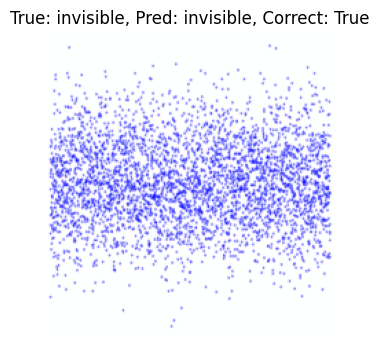

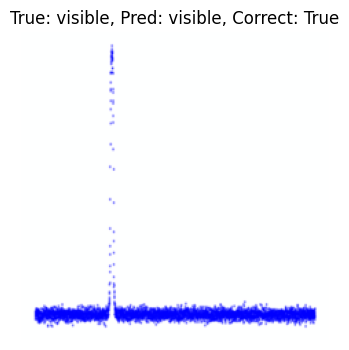

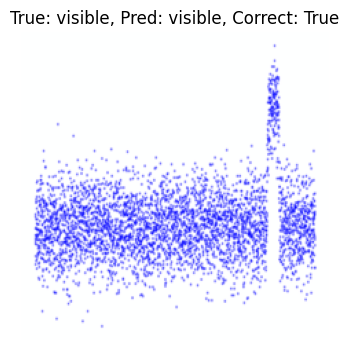

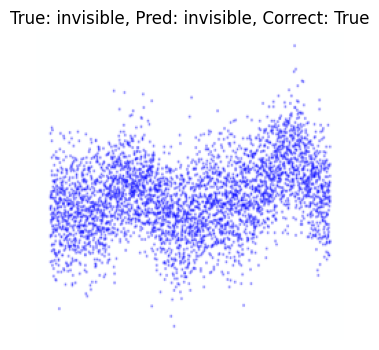

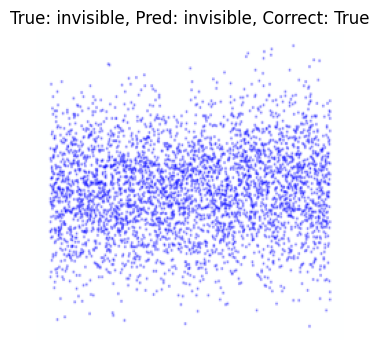

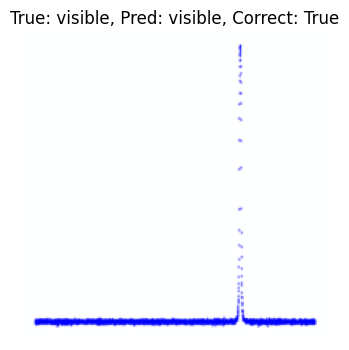

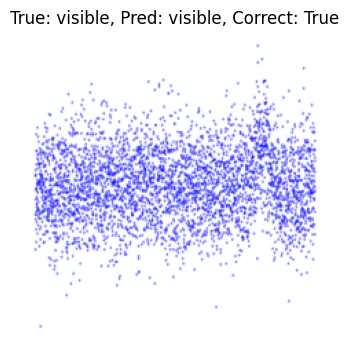

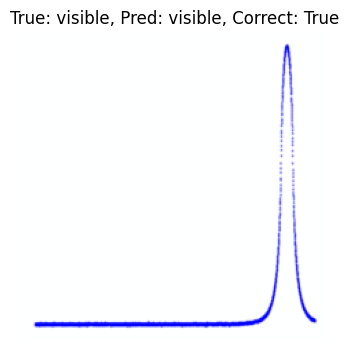

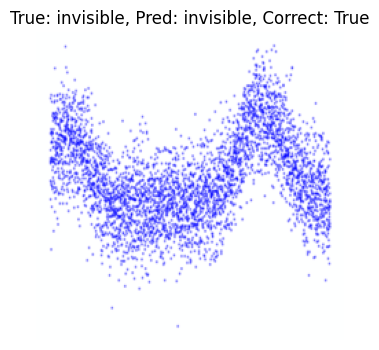

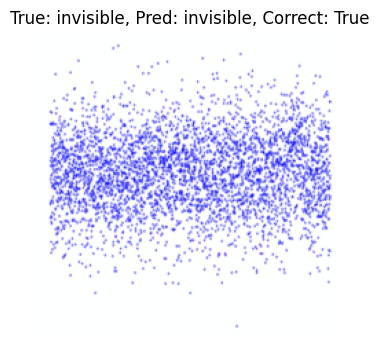

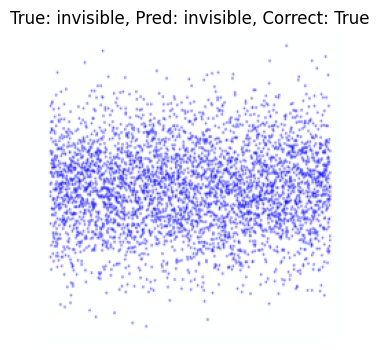

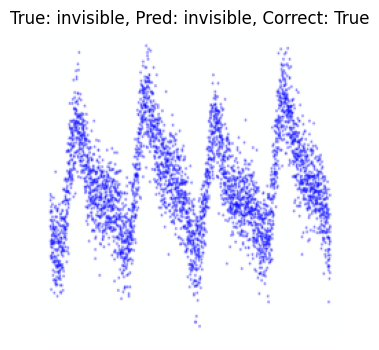

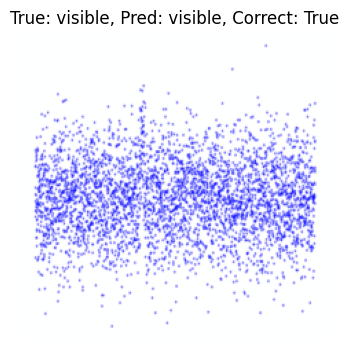

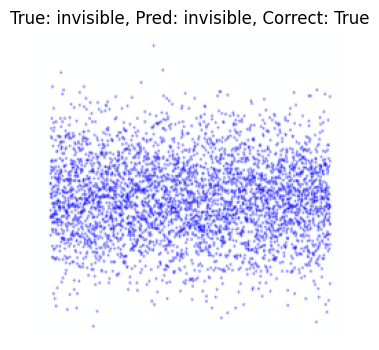

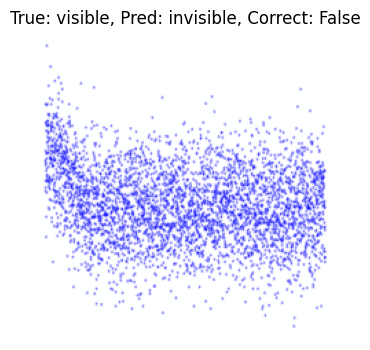

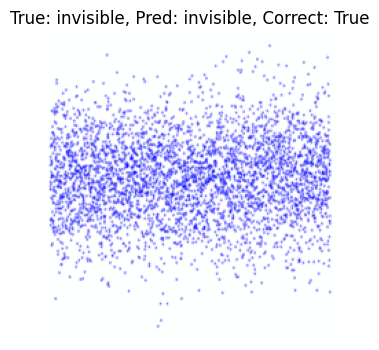

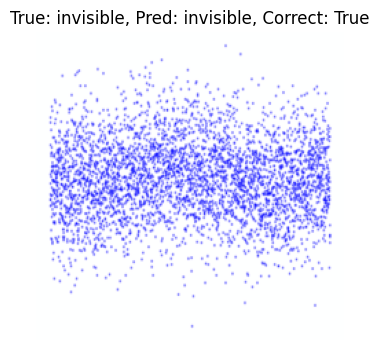

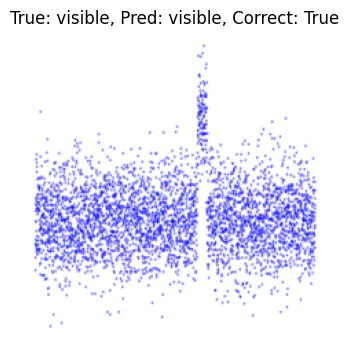

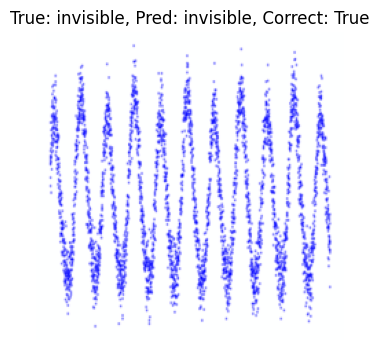

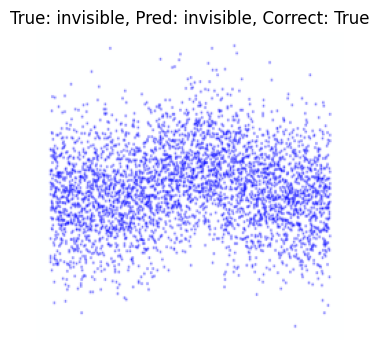

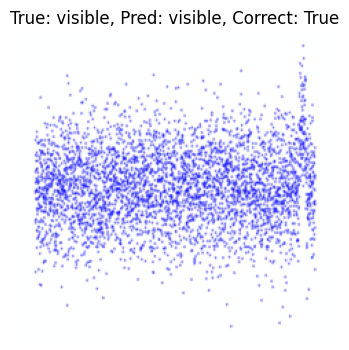

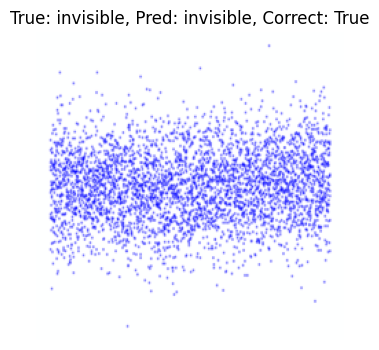

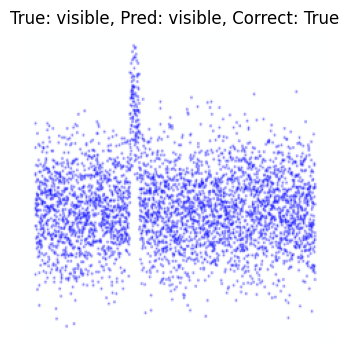

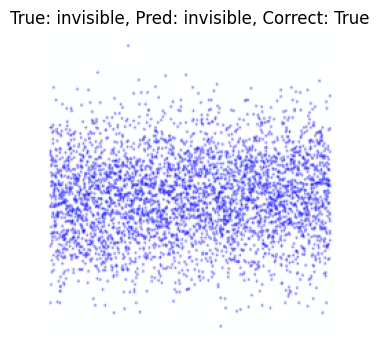

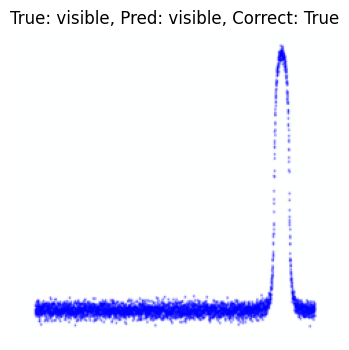

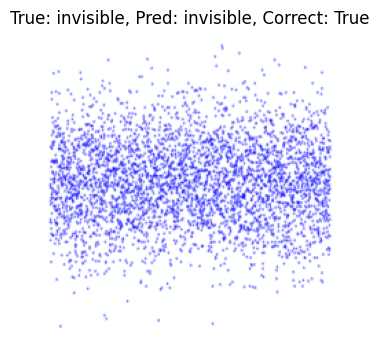

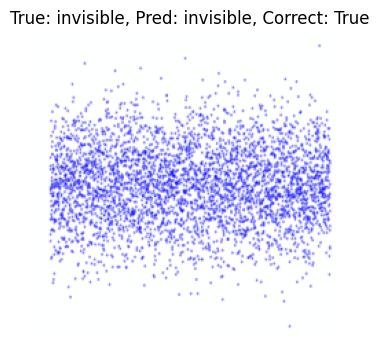

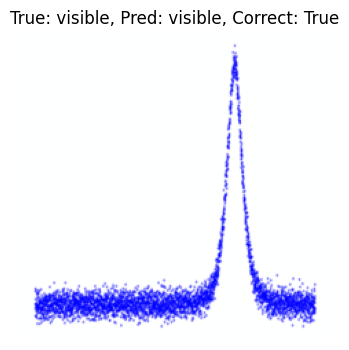

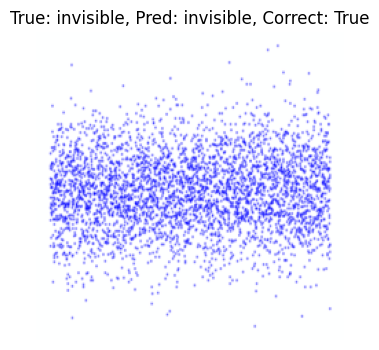

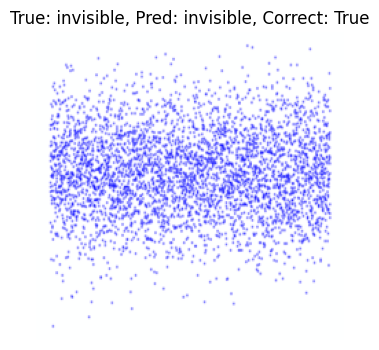

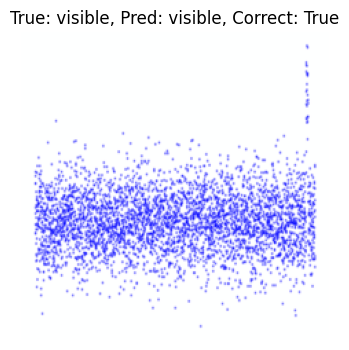

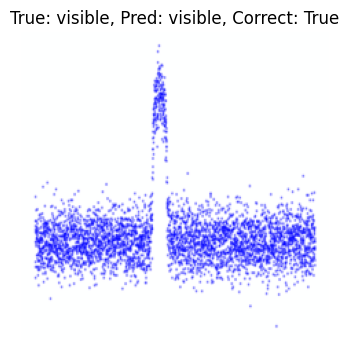

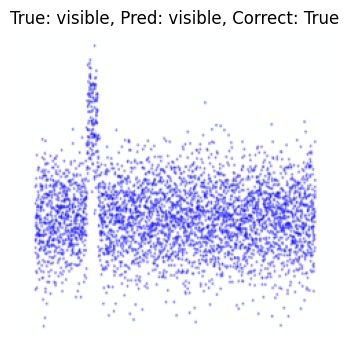

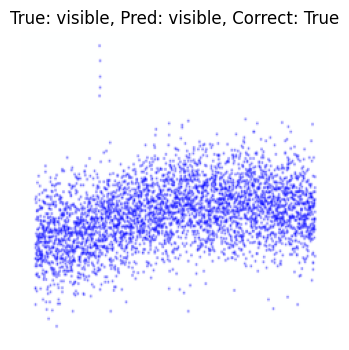

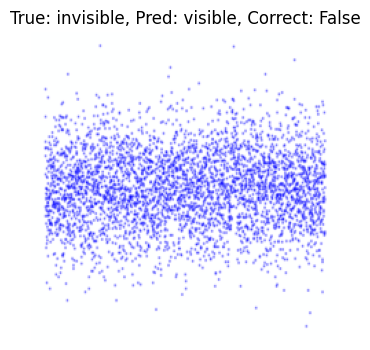

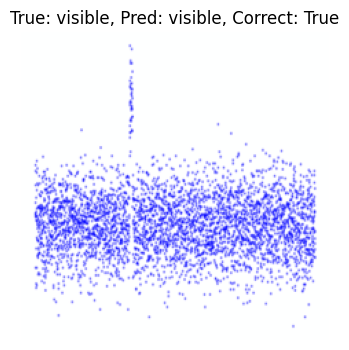

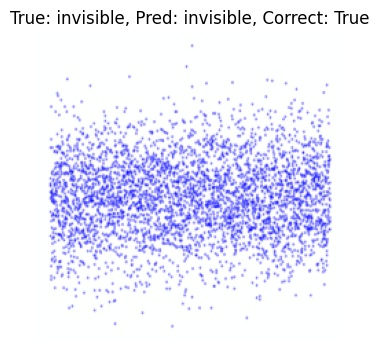

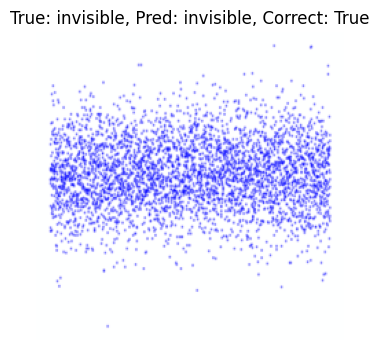

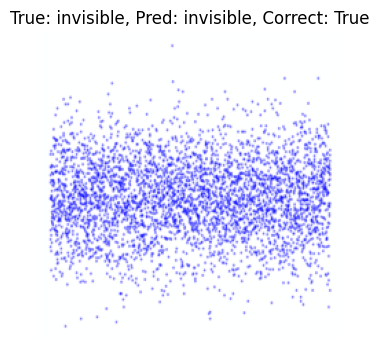

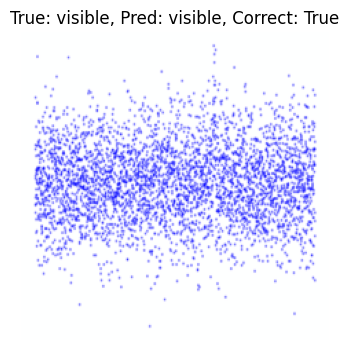

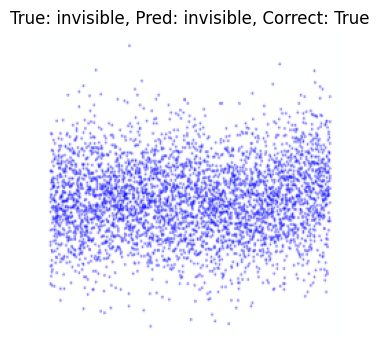

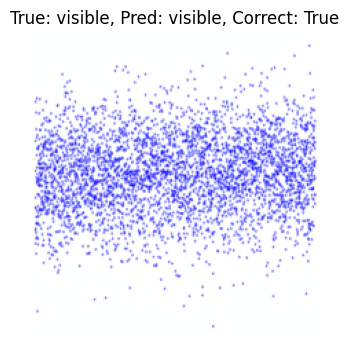

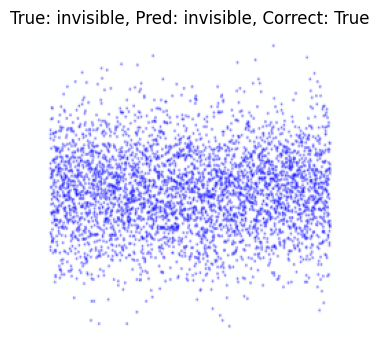

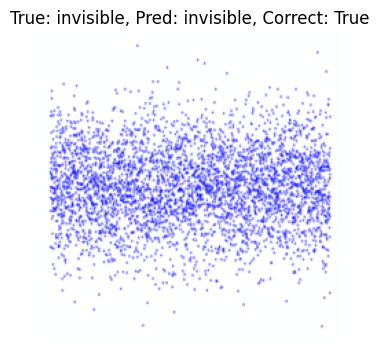

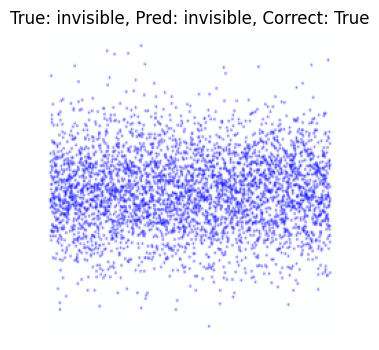

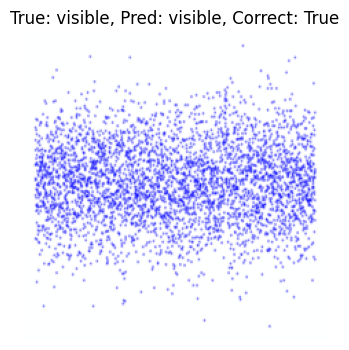

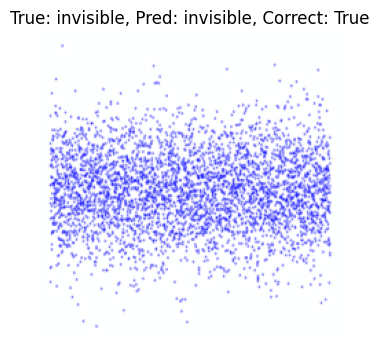

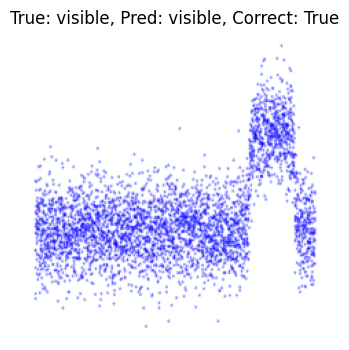

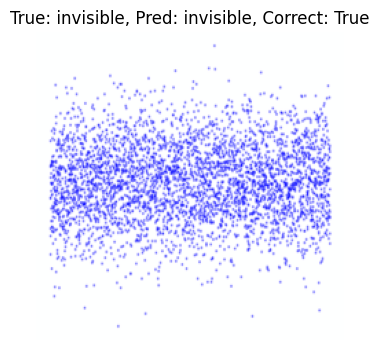

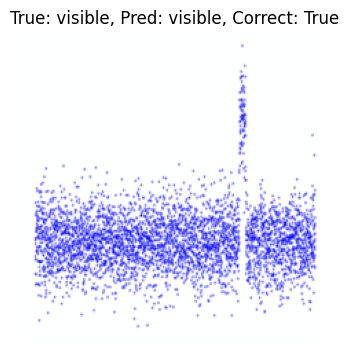

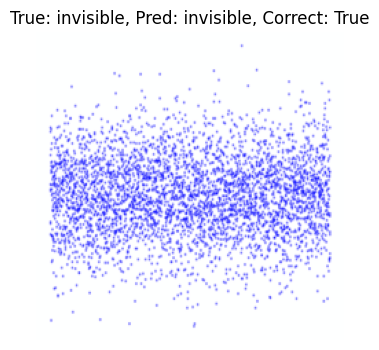

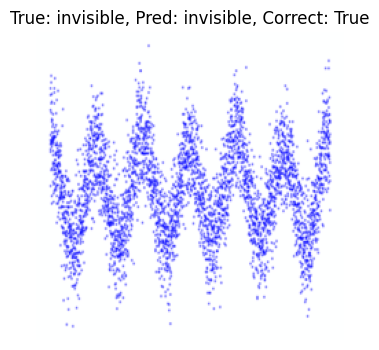

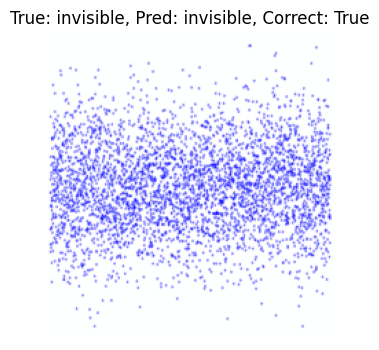

In [7]:
for images, labels in loader:
    images, labels = images.to(device), labels.to(device)
    with torch.no_grad():
        outputs = model(images)
        preds = torch.argmax(outputs, dim=1)
    
    for i in range(len(images)):
        plt.figure(figsize=(4, 4))
        img = images[i].permute(1, 2, 0).cpu().numpy()
        # Denormalize for display (approximate)
        img = img * [0.229, 0.224, 0.225] + [0.485, 0.456, 0.406]
        img = img.clip(0, 1)
        plt.imshow(img)
        plt.title(f"True: {dataset.classes[labels[i].item()]}, Pred: {dataset.classes[preds[i].item()]}, Correct: {labels[i].item() == preds[i].item()}")
        plt.axis('off')
        plt.show()